# Data exploratoire des données UAVSAR

**Papier 1 — estimation supervisée du crosstalk polarimétrique PolSAR par encodeur à valeurs complexes (CVNN).**

Ce notebook est la **première brique** du projet. Son but est de :

1. comprendre et **vérifier** le format réel des données UAVSAR téléchargées (pile *Stack SLC* coregistrée `Rosamd_35012_04`, tracks 31 à 35, 4 polarisations) ;
2. poser des **fonctions de lecture réutilisables** — elles vivent toutes dans [`src/uavsar_io.py`](../src/uavsar_io.py) et serviront telles quelles au pipeline suivant.

> **Hors périmètre ici.** Aucune baseline statistique (Quegan, Ainsworth), aucune chaîne d'injection de crosstalk, aucun modèle CVNN n'est implémenté dans ce notebook. On se limite à : lecture, vérification, visualisation, ossature d'extraction de patchs.

### Deux contraintes qui structurent tout le code

* **Mémoire.** Un `.slc` 1x1 pèse ~4,5 Gio, la pile complète ~90 Go. *Aucun fichier n'est jamais chargé entièrement en RAM* : tout passe par `numpy.memmap` (lecture paresseuse), et les lectures denses sont soit décimées, soit bornées à une tuile, avec un plafond mémoire explicite.
* **Ordre des canaux.** Le vecteur de diffusion suit la convention ONERA `s = [S_Hh, S_Vh, S_Hv, S_Vv]`, soit **`[HH, VH, HV, VV]`** — positions 2 et 3 permutées par rapport à l'ordre alphabétique. Cet ordre est figé dans la constante `POL_ORDER_ONERA` et utilisé partout.

## 1. Configuration

In [1]:
"""Configuration : imports, chemins relatifs à la racine du dépôt, graine aléatoire."""
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Racine du dépôt et accès au module réutilisable -------------------------
# Le kernel démarre dans notebooks/ ; on remonte jusqu'au marqueur .git pour ne
# manipuler que des chemins RELATIFS à la racine dans la suite du notebook.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import uavsar_io as uio  # noqa: E402  (import après ajustement de sys.path)

# --- Chemins (SEUL endroit du notebook où un chemin est écrit) ---------------
DATA_DIR = REPO_ROOT / "data" / "Rosamd_35012_04"
CORNER_REFLECTOR_CSV = REPO_ROOT / "data" / "corner_reflectors_rosamond.csv"  # optionnel

# --- Paramètres d'exploration (aucune dimension d'image ici : tout vient du .ann)
LOOKS = "1x1"          # multilook des .slc exploités
PREVIEW_MAX_SIZE = 2000  # cible en pixels sur le grand axe pour les aperçus décimés
TILE_SIZE = 512          # côté de la tuile de démonstration
PATCH_SIZE = 64          # côté des patchs du futur pipeline
SEED = 42

RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.interpolation": "nearest"})

print(f"Racine du dépôt   : {REPO_ROOT}")
print(f"Données           : {DATA_DIR.relative_to(REPO_ROOT)}  (existe : {DATA_DIR.is_dir()})")
print(f"Python            : {sys.version.split()[0]}")
print(f"numpy {np.__version__} · pandas {pd.__version__} · matplotlib {plt.matplotlib.__version__}")
print(f"Ordre des canaux  : {uio.POL_ORDER_ONERA}  (convention ONERA)")

Racine du dépôt   : /home/nicolas/Computer_Vision/crosstalk_estimation
Données           : data/Rosamd_35012_04  (existe : True)
Python            : 3.12.3
numpy 2.5.3 · pandas 3.0.5 · matplotlib 3.11.1
Ordre des canaux  : ('HH', 'VH', 'HV', 'VV')  (convention ONERA)


### Index des fichiers

`uio.discover_slc_files` parcourt le répertoire avec `glob`, décompose chaque nom de fichier
(`site_ligne_flightID_dataTake_date_L090POL_stack_BC_sN_1x1.slc`) et apparie chaque `.slc` à son `.ann`.

Le **numéro de track** (31–35) n'apparaît pas dans le nom de fichier : il est lu dans le `.ann`
(clé `Stack Line Number`), ce qui évite tout mapping codé en dur.

In [2]:
"""Découverte automatique des fichiers et construction de l'index track / polarisation."""
stack = uio.UavsarStack.from_dir(DATA_DIR, looks=LOOKS)

index = stack.index.copy()
index["slc_path"] = index["slc_path"].map(lambda p: p.relative_to(REPO_ROOT))
index["ann_path"] = index["ann_path"].map(lambda p: p.relative_to(REPO_ROOT))
index["slc_Gio"] = (stack.index["slc_bytes"] / 1024**3).round(2)

print(f"{len(stack.index)} fichiers .slc indexés · tracks : {stack.tracks}")
display(
    index[["track", "pol", "pol_index", "flight_id", "data_take", "date",
           "acquisition_date", "slc_Gio", "ann_exists", "slc_path"]]
)

20 fichiers .slc indexés · tracks : [31, 32, 33, 34, 35]


,track,pol,pol_index,flight_id,data_take,date,acquisition_date,slc_Gio,ann_exists,slc_path
0,31,HH,0,16002,001,160211,2016-02-11,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16002_001_16...
1,31,VH,1,16002,001,160211,2016-02-11,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16002_001_16...
2,31,HV,2,16002,001,160211,2016-02-11,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16002_001_16...
3,31,VV,3,16002,001,160211,2016-02-11,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16002_001_16...
4,32,HH,0,16052,001,160520,2016-05-20,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16052_001_16...
5,32,VH,1,16052,001,160520,2016-05-20,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16052_001_16...
6,32,HV,2,16052,001,160520,2016-05-20,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16052_001_16...
7,32,VV,3,16052,001,160520,2016-05-20,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16052_001_16...
8,33,HH,0,16053,001,160610,2016-06-10,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16053_001_16...
9,33,VH,1,16053,001,160610,2016-06-10,4.51,True,data/Rosamd_35012_04/Rosamd_35012_16053_001_16...


In [3]:
"""Mapping track -> (flightID, dataTake, date), reconstruit depuis les fichiers."""
mapping = (
    stack.index.groupby("track")
    .agg(flight_id=("flight_id", "first"),
         data_take=("data_take", "first"),
         acquisition_date=("acquisition_date", "first"),
         n_pol=("pol", "nunique"))
    .reset_index()
)
mapping["acquisition_date"] = mapping["acquisition_date"].dt.strftime("%d %b %Y")
display(mapping)

volume_gio = stack.index["slc_bytes"].sum() / 1024**3
print(f"Volume total des .slc {LOOKS} : {volume_gio:.1f} Gio "
      f"— d'où l'usage systématique de numpy.memmap ci-dessous.")

,track,flight_id,data_take,acquisition_date,n_pol
0,31,16002,001,11 Feb 2016,4
1,32,16052,001,20 May 2016,4
2,33,16053,001,10 Jun 2016,4
3,34,16060,009,16 Aug 2016,4
4,35,16074,005,20 Sep 2016,4


Volume total des .slc 1x1 : 90.3 Gio — d'où l'usage systématique de numpy.memmap ci-dessous.


## 2. Parsing des annotations `.ann`

Le fichier `.ann` est un ASCII `clé (unité) = valeur ; commentaire`. Le parseur de `uavsar_io` :

* ignore les commentaires (`;` en **début ou milieu** de ligne) ;
* découpe sur le **premier** `=` seulement — l'URL du produit contient elle-même des `=` ;
* détache l'unité entre parenthèses placée juste avant le `=` ;
* tente une conversion numérique ;
* ne suppose **aucun numéro de ligne fixe** (l'en-tête JPL demande d'ailleurs explicitement de
  chercher les paramètres par leur nom : *« search for parameters/value rather than placement in file »*).

In [4]:
"""Parsing d'un .ann de référence et repérage des clés par expression régulière."""
REFERENCE_TRACK = stack.tracks[0]
reference_ann_path = stack.row(REFERENCE_TRACK, "HH")["ann_path"]
ann_entries = uio.parse_ann_entries(reference_ann_path)
ann = uio.parse_ann(reference_ann_path)

print(f"{reference_ann_path.name}  →  {len(ann)} clés")
print("\nClés contenant 'Rows' ou 'Columns' (repérage par regex, aucune dimension en dur) :")
for key, value in uio.find_ann_keys(ann, r"Rows|Columns").items():
    print(f"  {key:<40} = {value}")

Rosamd_35012_16002_001_160211_L090HH_04_BC.ann  →  241 clés

Clés contenant 'Rows' ou 'Columns' (repérage par regex, aucune dimension en dur) :
  slc_1_1x1 Columns                        = 9874
  slc_1_1x1 Rows                           = 61349
  slc_1_1x4 Columns                        = 9874
  slc_1_1x4 Rows                           = 15338
  slc_1_2x8 Columns                        = 4937
  slc_1_2x8 Rows                           = 7669
  llh_1_2x8 Columns                        = 4937
  llh_1_2x8 Rows                           = 7669
  lkv_1_2x8 Columns                        = 4937
  lkv_1_2x8 Rows                           = 7669
  slc_1_1x1_mag.set_rows                   = 61349
  slc_1_1x1_phase.set_rows                 = 61349
  slc_1_1x4_mag.set_rows                   = 15338
  slc_1_1x4_phase.set_rows                 = 15338
  slc_1_2x8_mag.set_rows                   = 7669
  slc_1_2x8_phase.set_rows                 = 7669
  llh_1_2x8.set_rows                       = 7669


In [5]:
"""Métadonnées clés du produit, avec leurs unités déclarées."""
WANTED = [
    "Stack Line Number", "Polarization", "Acquisition Mode", "Look Direction",
    "Start Time of Acquisition", "SLC Data Units", "SLC Pixel Format",
    "SLC Bytes Per Pixel", "LLH Bytes Per Pixel",
    f"slc_1_{LOOKS} Rows", f"slc_1_{LOOKS} Columns",
    f"{LOOKS} SLC Range Pixel Spacing", f"{LOOKS} SLC Azimuth Pixel Spacing",
    f"Number of Range Looks in {LOOKS} SLC", f"Number of Azimuth Looks in {LOOKS} SLC",
    "Image Starting Slant Range", "Minimum Look Angle", "Maximum Look Angle",
    "Center Wavelength", "Bandwidth", "Number of Segments",
]
display(pd.DataFrame(
    [{"clé": k, "valeur": ann_entries[k].value, "unité": ann_entries[k].unit}
     for k in WANTED if k in ann_entries]
))

,clé,valeur,unité
0,Stack Line Number,31,-
1,Polarization,HH,&
2,Acquisition Mode,PolSAR,&
3,Look Direction,Left,&
4,Start Time of Acquisition,11-Feb-2016 01:59:28 UTC,&
5,SLC Data Units,linear amplitude and phase,&
6,SLC Pixel Format,Complex,&
7,SLC Bytes Per Pixel,8,bytes
8,LLH Bytes Per Pixel,12,bytes
9,slc_1_1x1 Rows,61349,pixels


In [6]:
"""Géométrie exploitable, et cohérence des dimensions ENTRE les 4 polarisations."""
geometry = stack.geometry(REFERENCE_TRACK, "HH")
print(f"Track {REFERENCE_TRACK} · {LOOKS} : {geometry.n_rows} lignes (azimut) "
      f"x {geometry.n_cols} colonnes (range)")
extent = geometry.extent_m()
print(f"Étendue approximative : {extent[0] / 1000:.1f} km en azimut "
      f"x {extent[1] / 1000:.1f} km en slant range")
print(f"Taille attendue du .slc : {geometry.expected_bytes:,} octets "
      f"({geometry.expected_bytes / 1024**3:.2f} Gio)\n")

geometry_table = stack.geometry_table(REFERENCE_TRACK)
display(geometry_table)

dimensions = geometry_table[["n_rows (azimut)", "n_cols (range)"]].drop_duplicates()
print(f"→ dimensions distinctes parmi les 4 polarisations de la track "
      f"{REFERENCE_TRACK} : {len(dimensions)} (attendu : 1)")

Track 31 · 1x1 : 61349 lignes (azimut) x 9874 colonnes (range)
Étendue approximative : 36.8 km en azimut x 16.4 km en slant range
Taille attendue du .slc : 4,846,080,208 octets (4.51 Gio)



,track,pol,looks,n_rows (azimut),n_cols (range),range_pixel_spacing_m,azimuth_pixel_spacing_m,starting_slant_range_km,min_look_angle_deg,max_look_angle_deg,center_wavelength_cm,n_range_looks,n_azimuth_looks,acquisition_start,expected_bytes
0,31,HH,1x1,61349,9874,1.665514,0.6,12.592754,21.321596,66.171221,23.840355,1,1,11-Feb-2016 01:59:28 UTC,4846080208
1,31,VH,1x1,61349,9874,1.665514,0.6,12.592754,21.321596,66.171221,23.840355,1,1,11-Feb-2016 01:59:28 UTC,4846080208
2,31,HV,1x1,61349,9874,1.665514,0.6,12.592754,21.321596,66.171221,23.840355,1,1,11-Feb-2016 01:59:28 UTC,4846080208
3,31,VV,1x1,61349,9874,1.665514,0.6,12.592754,21.321596,66.171221,23.840355,1,1,11-Feb-2016 01:59:28 UTC,4846080208


→ dimensions distinctes parmi les 4 polarisations de la track 31 : 1 (attendu : 1)


In [7]:
"""Cohérence des dimensions sur TOUTE la pile (5 tracks x 4 polarisations)."""
all_geometries = stack.geometry_table()
per_track = (
    all_geometries.groupby("track")[["n_rows (azimut)", "n_cols (range)"]]
    .nunique()
    .rename(columns=lambda c: f"{c} — nb valeurs distinctes")
)
display(per_track)
print("Formes rencontrées dans la pile :",
      sorted(set(zip(all_geometries["n_rows (azimut)"], all_geometries["n_cols (range)"]))))

,n_rows (azimut) — nb valeurs distinctes,n_cols (range) — nb valeurs distinctes
track,,
31,1,1
32,1,1
33,1,1
34,1,1
35,1,1


Formes rencontrées dans la pile : [(61349, 9874)]


## 3. Lecture d'un SLC en `numpy.memmap`

Le `.slc` est un binaire **brut, sans en-tête**, little-endian, 8 octets par pixel
(float32 réel puis float32 imaginaire) → `numpy.complex64`, de forme `(n_rows, n_cols)`
avec les dimensions **lues dans le `.ann`**.

`open_slc_memmap` vérifie au passage que `taille_fichier == n_rows × n_cols × 8` et lève une
erreur explicite sinon. L'objet retourné est une **vue paresseuse** : ouvrir les 20 fichiers
de la pile ne coûte rien en RAM.

In [8]:
"""Ouverture memmap et lecture d'une tuile pour prouver que la lecture est correcte."""
slc = stack.memmap(REFERENCE_TRACK, "HH")
print(f"type   : {type(slc).__name__}")
print(f"dtype  : {slc.dtype}  (little-endian : {uio.SLC_DTYPE.byteorder in '<=' })")
print(f"forme  : {slc.shape}  = (azimut, range)")
print(f"octets/pixel : {slc.dtype.itemsize}")

# Tuile centrée dans l'image : bornée à 512x512 complexes = 2 Mio, jamais l'image entière.
row0 = geometry.n_rows // 2
col0 = geometry.n_cols // 2 - TILE_SIZE // 2
tile = stack.read_window(REFERENCE_TRACK, "HH", row0, col0, TILE_SIZE, TILE_SIZE)

print(f"\nTuile [{row0}:{row0 + TILE_SIZE}, {col0}:{col0 + TILE_SIZE}] : "
      f"{tile.shape} {tile.dtype} — {tile.nbytes / 1024**2:.1f} Mio en RAM")
print(f"  |s|   min={np.abs(tile).min():.3e}  moyenne={np.abs(tile).mean():.3e}  "
      f"max={np.abs(tile).max():.3e}   (amplitude LINÉAIRE, pas dB)")
print(f"  phase : [{np.angle(tile).min():.2f}, {np.angle(tile).max():.2f}] rad")
print(f"  premiers pixels : {tile[0, :3]}")

type   : memmap
dtype  : complex64  (little-endian : True)
forme  : (61349, 9874)  = (azimut, range)
octets/pixel : 8

Tuile [30674:31186, 4681:5193] : (512, 512) complex64 — 2.0 Mio en RAM
  |s|   min=8.695e-05  moyenne=5.221e-02  max=1.054e+00   (amplitude LINÉAIRE, pas dB)
  phase : [-3.14, 3.14] rad
  premiers pixels : [ 0.00444019+0.01265624j -0.04186944+0.03841248j -0.03625402+0.03111842j]


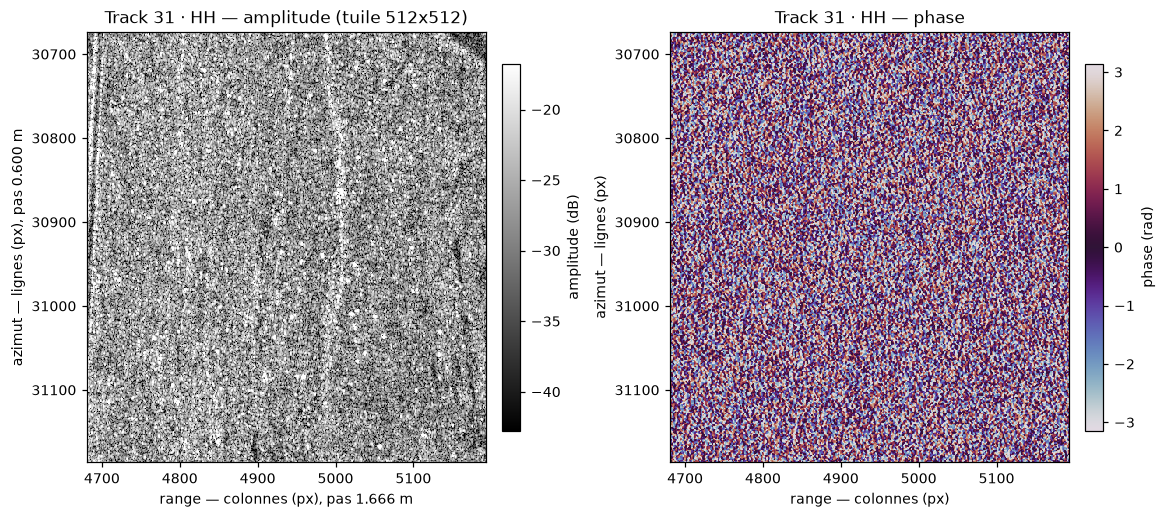

In [9]:
"""La tuile, en amplitude dB et en phase — la phase doit être un bruit uniforme sur [-pi, pi]."""
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)

# row_offset/col_offset : les deux panneaux sont gradués dans les coordonnées
# ABSOLUES de l'image pleine résolution, directement réutilisables ensuite.
uio.plot_amplitude_db(
    axes[0], uio.amplitude_db(tile), stride=1, row_offset=row0, col_offset=col0,
    geometry=geometry,
    title=f"Track {REFERENCE_TRACK} · HH — amplitude (tuile {TILE_SIZE}x{TILE_SIZE})",
)

phase = axes[1].imshow(np.angle(tile), cmap="twilight", vmin=-np.pi, vmax=np.pi,
                       origin="upper", aspect="auto",
                       extent=(col0, col0 + TILE_SIZE, row0 + TILE_SIZE, row0))
axes[1].set_xlabel("range — colonnes (px)")
axes[1].set_ylabel("azimut — lignes (px)")
axes[1].set_title(f"Track {REFERENCE_TRACK} · HH — phase")
fig.colorbar(phase, ax=axes[1], label="phase (rad)", fraction=0.046, pad=0.04)
plt.show()

## 4. Sanity checks

Assertions exécutables de bout en bout **en quelques secondes** : rien n'est lu intégralement,
les statistiques portent sur un échantillon décimé.

In [10]:
"""Bloc d'assertions : structure, tailles, dtype, contenu, cohérence inter-polarisations."""
expected_pols = set(uio.POL_ORDER_ONERA)
n_expected = len(stack.tracks) * len(expected_pols)
report = []

# -- (a) Complétude : 20 .slc + 20 .ann ---------------------------------------
missing_slc = [p for p in stack.index["slc_path"] if not Path(p).is_file()]
missing_ann = [p for p in stack.index["ann_path"] if not Path(p).is_file()]
assert not missing_slc, f"Fichiers .slc manquants : {missing_slc}"
assert not missing_ann, f"Fichiers .ann manquants : {missing_ann}"
assert len(stack.index) == n_expected, (
    f"{len(stack.index)} fichiers .slc indexés, {n_expected} attendus "
    f"({len(stack.tracks)} tracks x {len(expected_pols)} polarisations)."
)
report.append(("(a) 20 .slc + 20 .ann présents et indexés", f"{len(stack.index)} couples"))

# -- (b) Les 4 polarisations pour chaque track --------------------------------
for track in stack.tracks:
    got = set(stack.polarizations(track))
    assert got == expected_pols, f"Track {track} : polarisations {sorted(got)}, attendu {sorted(expected_pols)}"
report.append(("(b) 4 polarisations par track", ", ".join(uio.POL_ORDER_ONERA)))

# -- (c) taille fichier == n_rows * n_cols * 8 --------------------------------
for _, row in stack.index.iterrows():
    geom = stack.geometry(row["track"], row["pol"])
    assert row["slc_bytes"] == geom.expected_bytes, (
        f"{Path(row['slc_path']).name} : {row['slc_bytes']} octets, "
        f"{geom.expected_bytes} attendus ({geom.n_rows} x {geom.n_cols} x 8)."
    )
    assert geom.bytes_per_pixel == uio.SLC_BYTES_PER_PIXEL, (
        f"{Path(row['ann_path']).name} annonce {geom.bytes_per_pixel} octets/pixel, 8 attendus."
    )
report.append(("(c) taille == n_rows x n_cols x 8 (20 fichiers)", "OK"))

# -- (d) dtype complex64 sur chaque memmap ------------------------------------
for _, row in stack.index.iterrows():
    memmap = stack.memmap(row["track"], row["pol"])
    assert memmap.dtype == np.complex64, f"dtype {memmap.dtype} au lieu de complex64."
    assert memmap.shape == stack.geometry(row["track"], row["pol"]).shape
report.append(("(d) dtype complex64 + forme conforme au .ann", "20 memmaps"))

# -- (e) dimensions identiques entre polarisations d'une même track -----------
for track in stack.tracks:
    shapes = {pol: stack.geometry(track, pol).shape for pol in stack.polarizations(track)}
    assert len(set(shapes.values())) == 1, f"Track {track} : formes incohérentes {shapes}"
report.append(("(e) dimensions identiques entre polarisations", "5 tracks"))

# -- (f) contenu : pixels finis / non nuls sur un échantillon décimé ----------
# Échantillon: 1 pixel sur `sample_stride` dans chaque direction (~5 Mio en RAM).
sample_stride = uio.decimation_stride(geometry.shape, PREVIEW_MAX_SIZE)
finite_stats = []
for pol in uio.POL_ORDER_ONERA:
    sample, _ = stack.read_decimated(REFERENCE_TRACK, pol, stride=sample_stride)
    finite_ratio = float(np.isfinite(sample).mean())
    nonzero_ratio = float((np.abs(sample) > 0).mean())
    assert finite_ratio == 1.0, f"{pol} : {1 - finite_ratio:.2%} de pixels non finis (NaN/inf)."
    assert nonzero_ratio > 0.5, f"{pol} : seulement {nonzero_ratio:.1%} de pixels non nuls."
    finite_stats.append({"pol": pol, "pixels échantillonnés": sample.size,
                         "part finie": finite_ratio, "part non nulle": round(nonzero_ratio, 4)})
report.append((f"(f) pixels finis / non nuls (échantillon 1/{sample_stride})", "4 polarisations"))

display(pd.DataFrame(finite_stats))
print()
for label, detail in report:
    print(f"  ✓ {label:<52} {detail}")
print("\nTous les sanity checks passent.")

,pol,pixels échantillonnés,part finie,part non nulle
0,HH,631301,1.0,0.9961
1,VH,631301,1.0,0.9964
2,HV,631301,1.0,0.9964
3,VV,631301,1.0,0.9964



  ✓ (a) 20 .slc + 20 .ann présents et indexés            20 couples
  ✓ (b) 4 polarisations par track                        HH, VH, HV, VV
  ✓ (c) taille == n_rows x n_cols x 8 (20 fichiers)      OK
  ✓ (d) dtype complex64 + forme conforme au .ann         20 memmaps
  ✓ (e) dimensions identiques entre polarisations        5 tracks
  ✓ (f) pixels finis / non nuls (échantillon 1/31)       4 polarisations

Tous les sanity checks passent.


## 5. Aperçus visuels

Les images pleine résolution (61 349 × 9 874) ne peuvent évidemment pas être affichées ni chargées.
On travaille sur une version **décimée par pas** (`image[::stride, ::stride]`), et non moyennée :

* moyenner un SLC complexe sans multilook propre n'a pas de sens et lisserait le chatoiement,
  qui est précisément ce qu'on veut observer ;
* la décimation **en lignes** divise d'autant le volume réellement lu sur disque (une ligne pèse
  ~79 Kio, on n'en touche qu'une sur `stride`), ce qui rend l'aperçu praticable sur 4,5 Gio ;
* le tableau dense résultant fait ~5 Mio.

Les axes sont gradués en pixels **pleine résolution** : les coordonnées lues sur ces figures
s'utilisent directement dans `read_scattering_patch`.

In [11]:
"""Aperçus décimés des 4 polarisations d'une track (~2 s de lecture par canal)."""
previews, stride = {}, None
for pol in uio.POL_ORDER_ONERA:
    image, stride = stack.read_decimated(REFERENCE_TRACK, pol, target_max_size=PREVIEW_MAX_SIZE)
    previews[pol] = image

preview_db = {pol: uio.amplitude_db(image) for pol, image in previews.items()}
first = previews[uio.POL_ORDER_ONERA[0]]
print(f"stride = {stride} → aperçu {first.shape} "
      f"({first.nbytes / 1024**2:.1f} Mio par canal, contre "
      f"{geometry.expected_bytes / 1024**3:.2f} Gio pour l'image complète)")

stride = 31 → aperçu (1979, 319) (4.8 Mio par canal, contre 4.51 Gio pour l'image complète)


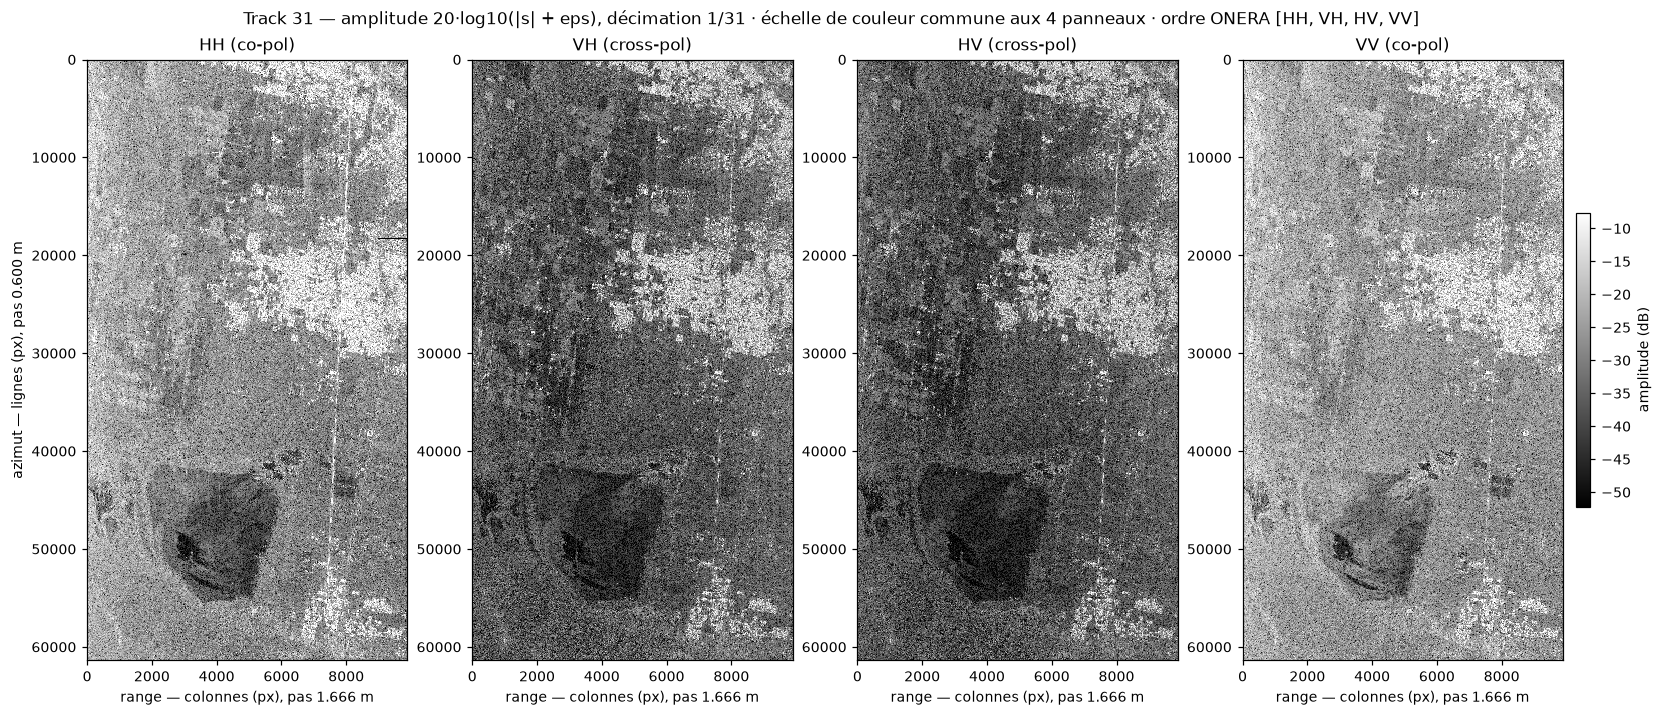

In [12]:
"""Les 4 canaux côte à côte, dans l'ordre ONERA [HH, VH, HV, VV]."""
# Échelle de couleur COMMUNE aux 4 panneaux (percentiles calculés sur l'ensemble
# des canaux) : c'est la condition pour qu'une seule barre de couleur soit
# valable pour toute la figure, et pour que le déficit de ~10 dB de la
# cross-polarisation se lise directement à l'image.
pooled = np.concatenate([image.ravel() for image in preview_db.values()])
vmin, vmax = np.percentile(pooled, [2, 98])

fig, axes = plt.subplots(1, 4, figsize=(15, 6.4), constrained_layout=True)
for ax, pol in zip(axes, uio.POL_ORDER_ONERA):
    kind = "co-pol" if pol in uio.CO_POL else "cross-pol"
    uio.plot_amplitude_db(
        ax, preview_db[pol], stride=stride, geometry=geometry, vmin=vmin, vmax=vmax,
        title=f"{pol} ({kind})", add_colorbar=(pol == uio.POL_ORDER_ONERA[-1]),
    )
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle(
    f"Track {REFERENCE_TRACK} — amplitude 20·log10(|s| + eps), décimation 1/{stride} "
    f"· échelle de couleur commune aux 4 panneaux · ordre ONERA [HH, VH, HV, VV]",
    fontsize=11,
)
plt.show()

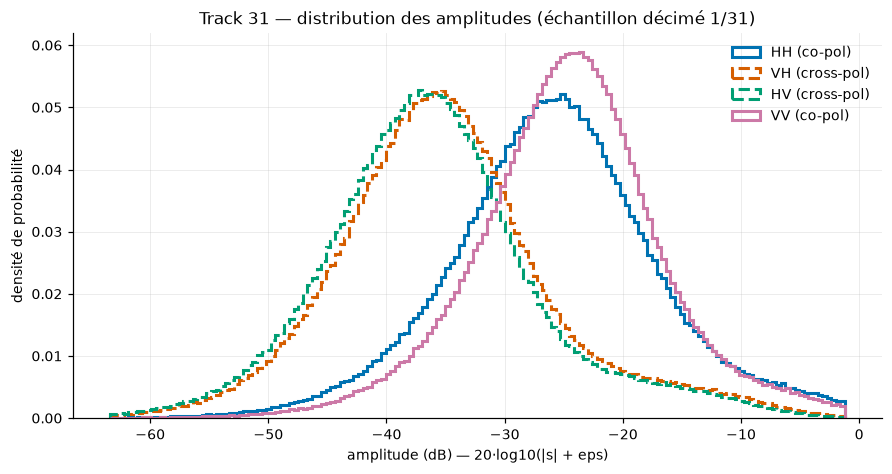

,pol,type,médiane (dB),moyenne (dB),p98 (dB),puissance moyenne (dB)
0,HH,co-pol,-25.80,-26.41,-3.68,-10.48
1,VH,cross-pol,-35.66,-35.82,-11.38,-20.80
2,HV,cross-pol,-36.61,-36.84,-12.77,-22.22
3,VV,co-pol,-24.51,-25.32,-5.82,-14.16


In [13]:
"""Distribution des amplitudes : la co-pol domine nettement la cross-pol."""
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
uio.plot_amplitude_histogram(ax, preview_db)
ax.set_title(f"Track {REFERENCE_TRACK} — distribution des amplitudes (échantillon décimé 1/{stride})")
plt.show()

# Table de référence : l'identité des courbes ne repose jamais sur la seule couleur.
summary = pd.DataFrame([
    {
        "pol": pol,
        "type": "co-pol" if pol in uio.CO_POL else "cross-pol",
        "médiane (dB)": round(float(np.median(preview_db[pol])), 2),
        "moyenne (dB)": round(float(preview_db[pol].mean()), 2),
        "p98 (dB)": round(float(np.percentile(preview_db[pol], 98)), 2),
        "puissance moyenne (dB)": round(float(10 * np.log10(np.mean(np.abs(previews[pol]) ** 2))), 2),
    }
    for pol in uio.POL_ORDER_ONERA
])
display(summary)

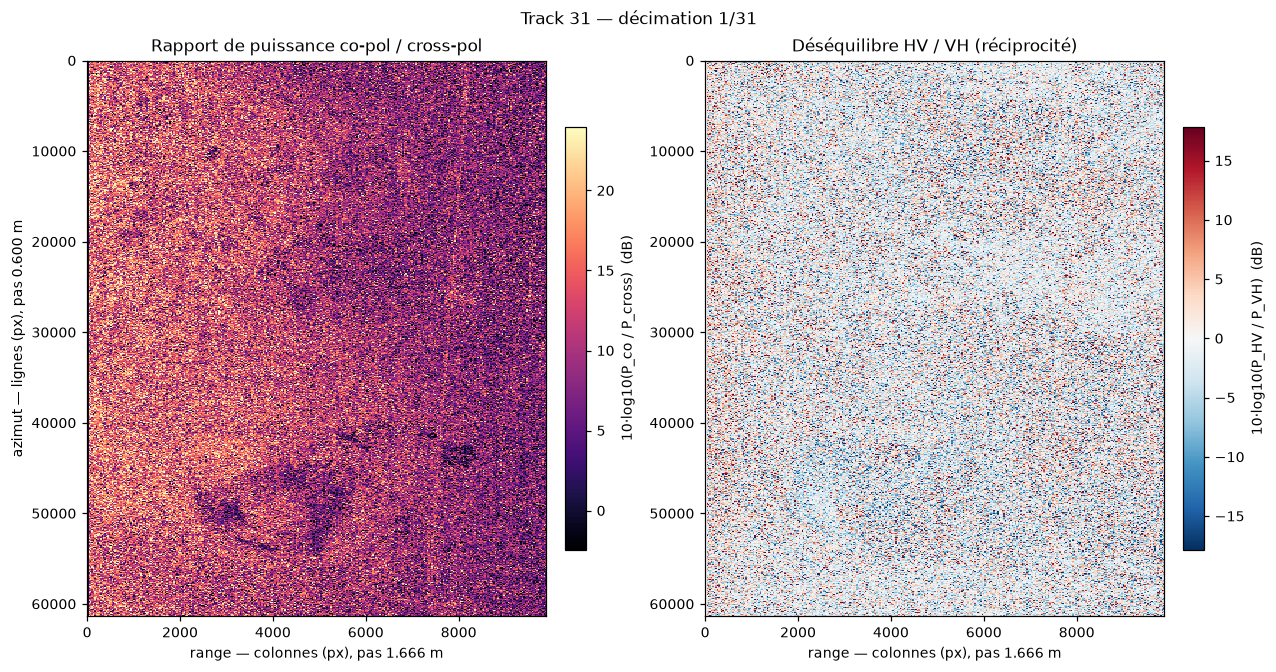

Rapport co/cross médian      : +10.46 dB
Déséquilibre HV/VH médian    : -1.15 dB
Cohérence complexe |<HV, VH>| : 0.914  (1 = réciprocité parfaite)

Note : les 4 canaux restent conservés distincts — HV et VH ne sont JAMAIS fusionnés,
l'écart entre eux fait partie du signal à estimer.


In [14]:
"""Comparaison co-pol (HH, VV) vs cross-pol (HV, VH), et symétrie HV/VH."""
co_power = np.mean([np.abs(previews[p]) ** 2 for p in uio.CO_POL], axis=0)
cross_power = np.mean([np.abs(previews[p]) ** 2 for p in uio.CROSS_POL], axis=0)
eps = 1e-12

fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.0), constrained_layout=True)

ratio_db = 10 * np.log10((co_power + eps) / (cross_power + eps))
# Le rapport co/cross est une grandeur de MAGNITUDE : sur cette scène il est
# quasiment partout positif (la co-pol domine). On utilise donc une rampe
# séquentielle à une seule teinte, bornée par les percentiles des données ; une
# palette divergente centrée sur 0 dB gaspillerait la moitié de sa dynamique.
low, high = np.percentile(ratio_db, [2, 98])
mappable = axes[0].imshow(ratio_db, cmap="magma", vmin=low, vmax=high, origin="upper",
                          aspect="auto",
                          extent=(0, ratio_db.shape[1] * stride, ratio_db.shape[0] * stride, 0))
axes[0].set_xlabel(f"range — colonnes (px), pas {geometry.range_pixel_spacing_m:.3f} m")
axes[0].set_ylabel(f"azimut — lignes (px), pas {geometry.azimuth_pixel_spacing_m:.3f} m")
axes[0].set_title("Rapport de puissance co-pol / cross-pol")
fig.colorbar(mappable, ax=axes[0], label="10·log10(P_co / P_cross)  (dB)",
             fraction=0.046, pad=0.04)

# Symétrie HV / VH : la réciprocité fait attendre S_Hv ~ S_Vh ; l'écart résiduel
# est justement une des empreintes du crosstalk que le Papier 1 cherche à estimer.
imbalance_db = 10 * np.log10((np.abs(previews["HV"]) ** 2 + eps) /
                             (np.abs(previews["VH"]) ** 2 + eps))
# Ici en revanche le 0 dB est un vrai point de bascule (HV plus fort / VH plus
# fort) : palette divergente à deux pôles, neutre au centre, bornes symétriques.
imbalance_limit = float(np.percentile(np.abs(imbalance_db), 98))
mappable = axes[1].imshow(imbalance_db, cmap="RdBu_r", vmin=-imbalance_limit, vmax=imbalance_limit,
                          origin="upper", aspect="auto",
                          extent=(0, imbalance_db.shape[1] * stride, imbalance_db.shape[0] * stride, 0))
axes[1].set_xlabel(f"range — colonnes (px), pas {geometry.range_pixel_spacing_m:.3f} m")
axes[1].set_ylabel("")
axes[1].set_title("Déséquilibre HV / VH (réciprocité)")
fig.colorbar(mappable, ax=axes[1], label="10·log10(P_HV / P_VH)  (dB)", fraction=0.046, pad=0.04)

fig.suptitle(f"Track {REFERENCE_TRACK} — décimation 1/{stride}", fontsize=11)
plt.show()

print(f"Rapport co/cross médian      : {np.median(ratio_db):+.2f} dB")
print(f"Déséquilibre HV/VH médian    : {np.median(imbalance_db):+.2f} dB")
correlation = np.abs(np.vdot(previews["HV"].ravel(), previews["VH"].ravel())) / (
    np.linalg.norm(previews["HV"]) * np.linalg.norm(previews["VH"]))
print(f"Cohérence complexe |<HV, VH>| : {correlation:.3f}  (1 = réciprocité parfaite)")
print("\nNote : les 4 canaux restent conservés distincts — HV et VH ne sont JAMAIS fusionnés,")
print("l'écart entre eux fait partie du signal à estimer.")

## 6. Vecteur de diffusion et extraction de patchs

`stack.read_scattering_patch(track, row, col, size=64)` lit les 4 memmaps de la track et renvoie
un tenseur complexe `(4, size, size)` dans l'ordre **ONERA `[HH, VH, HV, VV]`**.

C'est l'**ossature de l'extraction de patchs du futur pipeline** : les baselines statistiques
comme le CVNN consommeront exactement ce tenseur. La permutation VH ↔ HV par rapport à l'ordre
alphabétique est essentielle — elle conditionne le remapping `u↔z` / `v↔w` des paramètres de
crosstalk dans le modèle de distorsion.

In [15]:
"""Extraction d'un patch (4, 64, 64) à une position tirée aléatoirement (graine fixée)."""
margin = PATCH_SIZE
patch_row = int(RNG.integers(margin, geometry.n_rows - margin - PATCH_SIZE))
patch_col = int(RNG.integers(margin, geometry.n_cols - margin - PATCH_SIZE))

patch = stack.read_scattering_patch(REFERENCE_TRACK, patch_row, patch_col, size=PATCH_SIZE)

print(f"Position (azimut, range) : ({patch_row}, {patch_col})")
print(f"forme  : {patch.shape}   (canaux, azimut, range)")
print(f"dtype  : {patch.dtype}")
print(f"RAM    : {patch.nbytes / 1024:.1f} Kio")
print(f"ordre  : {uio.POL_ORDER_ONERA}\n")

assert patch.shape == (4, PATCH_SIZE, PATCH_SIZE), "Le patch doit être de forme (4, size, size)."
assert patch.dtype == np.complex64, "Le patch doit rester en complex64."
for channel, pol in enumerate(uio.POL_ORDER_ONERA):
    expected = stack.read_window(REFERENCE_TRACK, pol, patch_row, patch_col, PATCH_SIZE, PATCH_SIZE)
    assert np.array_equal(patch[channel], expected), (
        f"Canal {channel} ne correspond pas à la polarisation {pol} : l'ordre ONERA est rompu."
    )
print("✓ Chaque canal correspond bien à la polarisation attendue de l'ordre ONERA.")

display(pd.DataFrame([
    {"canal": channel, "symbole": symbol, "pol (Rx Tx)": pol,
     "|s| moyen": float(np.abs(patch[channel]).mean()),
     "puissance (dB)": round(float(10 * np.log10(np.mean(np.abs(patch[channel]) ** 2))), 2)}
    for channel, (pol, symbol) in enumerate(
        zip(uio.POL_ORDER_ONERA, ["S_Hh", "S_Vh", "S_Hv", "S_Vv"]))
]))

Position (azimut, range) : (5522, 7557)
forme  : (4, 64, 64)   (canaux, azimut, range)
dtype  : complex64
RAM    : 128.0 Kio
ordre  : ('HH', 'VH', 'HV', 'VV')

✓ Chaque canal correspond bien à la polarisation attendue de l'ordre ONERA.


,canal,symbole,pol (Rx Tx),|s| moyen,puissance (dB)
0,0,S_Hh,HH,0.039915,-26.64
1,1,S_Vh,VH,0.020392,-32.61
2,2,S_Hv,HV,0.017494,-34.04
3,3,S_Vv,VV,0.052488,-24.41


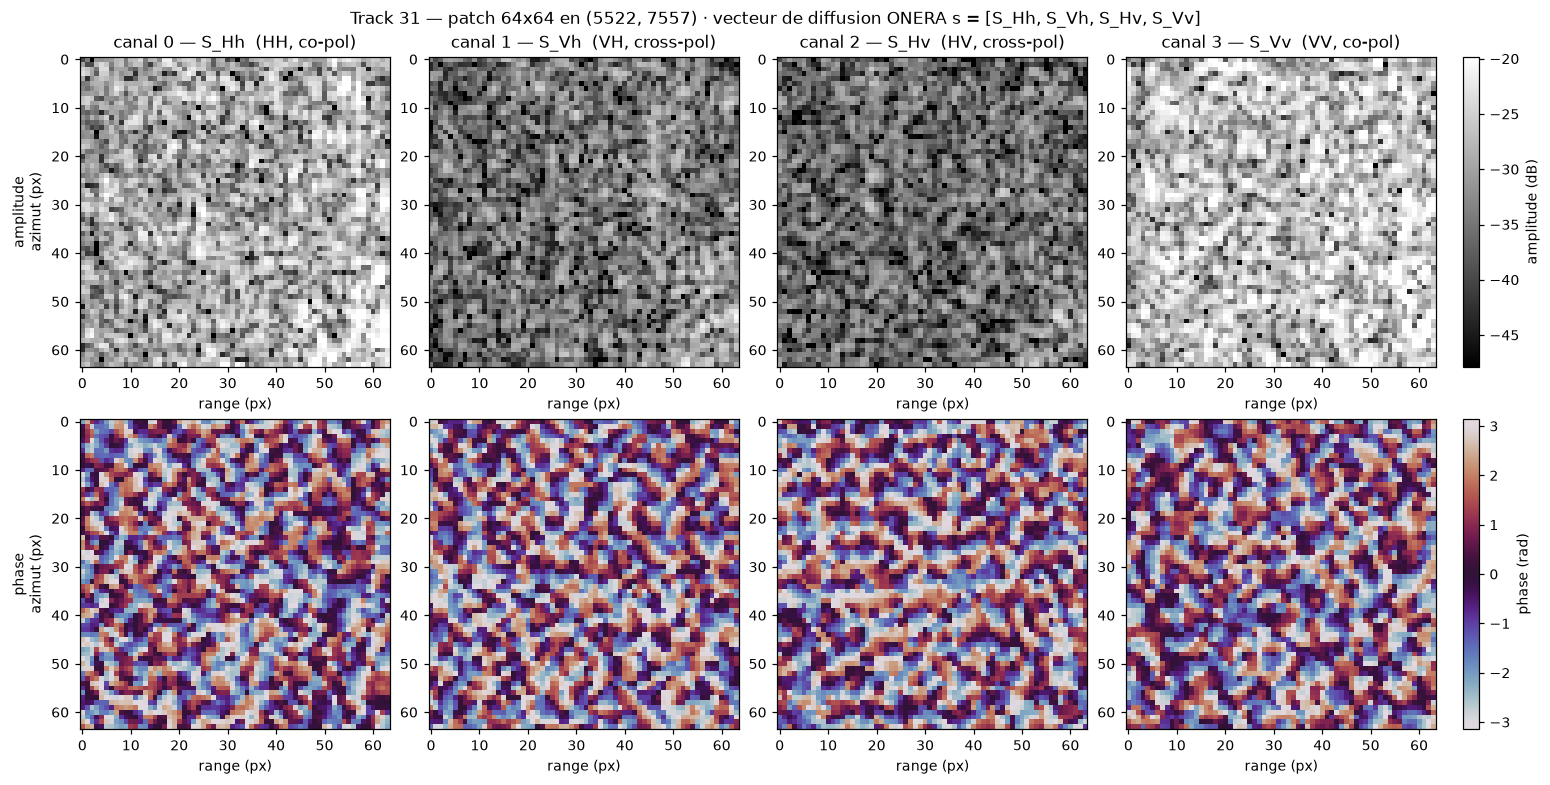

In [16]:
"""Le patch, canal par canal : amplitude (haut) et phase (bas)."""
fig, axes = plt.subplots(2, 4, figsize=(14, 7.0), constrained_layout=True)
symbols = ["S_Hh", "S_Vh", "S_Hv", "S_Vv"]

patch_db = uio.amplitude_db(patch)
vmin, vmax = np.percentile(patch_db, [2, 98])
for channel, (pol, symbol) in enumerate(zip(uio.POL_ORDER_ONERA, symbols)):
    amplitude = axes[0, channel].imshow(patch_db[channel], cmap="gray", vmin=vmin, vmax=vmax)
    kind = "co-pol" if pol in uio.CO_POL else "cross-pol"
    axes[0, channel].set_title(f"canal {channel} — {symbol}  ({pol}, {kind})")
    phase = axes[1, channel].imshow(np.angle(patch[channel]), cmap="twilight",
                                    vmin=-np.pi, vmax=np.pi)
    for ax in (axes[0, channel], axes[1, channel]):
        ax.set_xlabel("range (px)")
    if channel == 0:
        axes[0, 0].set_ylabel("amplitude\nazimut (px)")
        axes[1, 0].set_ylabel("phase\nazimut (px)")

fig.colorbar(amplitude, ax=axes[0, :], label="amplitude (dB)", fraction=0.025, pad=0.02)
fig.colorbar(phase, ax=axes[1, :], label="phase (rad)", fraction=0.025, pad=0.02)
fig.suptitle(
    f"Track {REFERENCE_TRACK} — patch {PATCH_SIZE}x{PATCH_SIZE} en ({patch_row}, {patch_col}) "
    f"· vecteur de diffusion ONERA s = [S_Hh, S_Vh, S_Hv, S_Vv]",
    fontsize=11,
)
plt.show()

## 7. Trièdres de calibration, `.llh` et `.lkv`

Les trièdres du réseau de Rosamond (IDs 13, 14, 15, 17, 18, 20, 21, 22) serviront plus tard de
référence de calibration. Leur CSV n'est pas fourni avec le produit Stack SLC : il se récupère
sur la page calibration du JPL.

Les fichiers `.llh` (lat/lon/hauteur) et `.lkv` (vecteur de visée ENU) sont des float32
little-endian, 12 octets/pixel, **produits en 2x8** alors que les `.slc` exploités ici sont en
**1x1** : les deux grilles ne coïncident pas. On se contente à ce stade de savoir les lire ;
l'appariement précis trièdre → pixel sera traité dans une brique ultérieure.

In [17]:
"""Trièdres de calibration, si le CSV est disponible."""
TARGET_CORNER_IDS = [13, 14, 15, 17, 18, 20, 21, 22]

corners = uio.load_corner_reflectors(CORNER_REFLECTOR_CSV, ids=TARGET_CORNER_IDS)
if corners is None:
    print(f"CSV des trièdres absent : {CORNER_REFLECTOR_CSV.relative_to(REPO_ROOT)}")
    print("→ à récupérer plus tard sur la page calibration du JPL "
          "(https://uavsar.jpl.nasa.gov/cgi-bin/calibration.pl).")
    print(f"→ trièdres visés pour ce site : {TARGET_CORNER_IDS}")
    print("  colonnes attendues : ID, latitude, longitude, hauteur, azimut, "
          "élévation, longueur de côté.")
else:
    print(f"{len(corners)} trièdres chargés parmi {TARGET_CORNER_IDS}")
    display(corners)

CSV des trièdres absent : data/corner_reflectors_rosamond.csv
→ à récupérer plus tard sur la page calibration du JPL (https://uavsar.jpl.nasa.gov/cgi-bin/calibration.pl).
→ trièdres visés pour ce site : [13, 14, 15, 17, 18, 20, 21, 22]
  colonnes attendues : ID, latitude, longitude, hauteur, azimut, élévation, longueur de côté.


In [18]:
"""Aperçu des .llh / .lkv (grille 2x8, distincte de celle des .slc 1x1)."""
vector_shape = (ann[f"llh_1_2x8 Rows"], ann[f"llh_1_2x8 Columns"])
print(f"Grille 2x8 (llh/lkv) : {vector_shape}   vs   SLC {LOOKS} : {geometry.shape}")
print(f"Facteur : {geometry.n_rows / vector_shape[0]:.0f} en azimut, "
      f"{geometry.n_cols / vector_shape[1]:.0f} en range\n")

for suffix, channels, unit in [(".llh", ["latitude", "longitude", "hauteur"], "deg/deg/m"),
                               (".lkv", ["est", "nord", "haut"], "m")]:
    matches = sorted(DATA_DIR.glob(f"*{suffix}"))
    if not matches:
        print(f"Aucun fichier {suffix} trouvé dans {DATA_DIR.relative_to(REPO_ROOT)}.")
        continue
    vectors = uio.open_vector_memmap(matches[0], vector_shape)
    # Coin 4x4 uniquement : lecture bornée, quelques centaines d'octets.
    corner = np.asarray(vectors[:4, :4, :])
    print(f"{matches[0].name}")
    print(f"  memmap {vectors.dtype} {vectors.shape} — canaux {channels} ({unit})")
    for channel, name in enumerate(channels):
        print(f"    {name:<10} coin[0,0] = {corner[0, 0, channel]:.6f}")
    print()

Grille 2x8 (llh/lkv) : (7669, 4937)   vs   SLC 1x1 : (61349, 9874)
Facteur : 8 en azimut, 2 en range

Rosamd_35012_04_BC_s1_2x8.llh
  memmap float32 (7669, 4937, 3) — canaux ['latitude', 'longitude', 'hauteur'] (deg/deg/m)
    latitude   coin[0,0] = 34.596546
    longitude  coin[0,0] = -117.913582
    hauteur    coin[0,0] = 784.642639

Rosamd_35012_04_BC_s1_2x8.lkv
  memmap float32 (7669, 4937, 3) — canaux ['est', 'nord', 'haut'] (m)
    est        coin[0,0] = -4628.636719
    nord       coin[0,0] = -233.998459
    haut       coin[0,0] = -11709.021484



## 8. Récapitulatif et suite

### Ce qui est établi

| Élément | Valeur (lue dans les `.ann`, jamais codée en dur) |
|---|---|
| Pile | `Rosamd_35012_04` — Rosamond, CA (réseau de calibration) |
| Tracks | 31 → 35, une par date de 2016 (11 fév., 20 mai, 10 juin, 16 août, 20 sept.) |
| Polarisations | 4 par track → **20 `.slc` + 20 `.ann`** |
| Dimensions `.slc` 1x1 | **61 349 lignes (azimut) × 9 874 colonnes (range)**, identiques sur toute la pile |
| Format `.slc` | binaire brut sans en-tête, little-endian, 8 octets/pixel → `complex64`, amplitude **linéaire**, géométrie *slant range* |
| Pas pixel | **1,666 m** en range, **0,600 m** en azimut (1 vue en range, 1 en azimut) |
| Étendue | ≈ 36,8 km (azimut) × 16,4 km (slant range) |
| Slant range initial | 12,593 km · angles de visée 21,3° → 66,2° |
| Longueur d'onde | 23,84 cm (bande L), bande passante 80 MHz |
| Volume | 4,51 Gio par fichier, **90,3 Gio** pour la pile → `numpy.memmap` obligatoire |
| `.llh` / `.lkv` | float32 little-endian, 12 octets/pixel, grille **2x8** (7 669 × 4 937) ≠ grille SLC 1x1 |

### Ordre des canaux retenu

**`POL_ORDER_ONERA = ("HH", "VH", "HV", "VV")`** — convention ONERA `s = [S_Hh, S_Vh, S_Hv, S_Vv]`,
positions 2 et 3 permutées par rapport à l'ordre alphabétique. Cet ordre conditionne le
remapping `u↔z` / `v↔w` des paramètres de crosstalk : toute pile `(4, H, W)` du projet doit le
respecter. Les 4 canaux restent **distincts** — HV et VH ne sont jamais fusionnés, l'écart entre
eux fait partie du signal à estimer.

### Ossature réutilisable posée dans [`src/uavsar_io.py`](../src/uavsar_io.py)

`discover_slc_files` · `parse_ann` / `parse_ann_entries` / `find_ann_keys` · `read_slc_geometry` ·
`open_slc_memmap` / `open_vector_memmap` · `read_window` · `read_decimated` / `decimation_stride` ·
`read_scattering_patch` · `amplitude_db` / `plot_amplitude_db` / `plot_amplitude_histogram` ·
`load_corner_reflectors`, le tout derrière la façade `UavsarStack`.

### Prochaines étapes (non implémentées ici)

1. **Récupérer le CSV des trièdres** (page calibration JPL) et résoudre l'appariement
   trièdre → pixel, ce qui suppose de passer de la grille `.llh` 2x8 à la grille SLC 1x1.
2. **Baselines statistiques** : estimateurs de crosstalk de Quegan et d'Ainsworth, sur des
   fenêtres de la pile, pour servir de point de comparaison au CVNN.
3. **Chaîne d'injection** : modèle de distorsion polarimétrique appliqué à des données supposées
   propres, afin de produire un jeu supervisé (crosstalk connu → vérité terrain).
4. **Extraction de patchs à grande échelle** : sur la base de `read_scattering_patch`, avec
   stratégie d'échantillonnage, filtrage des zones non imagées et découpage train/val/test.
5. **Encodeur CVNN** : entraînement supervisé de l'estimateur à valeurs complexes, en s'appuyant
   sur le framework maison `cvnn_framework/`.